# Step 1b — Adaptive (local) Otsu vs Otsu baseline

Result: `run_adaptive` from `src/adaptive_thresholding.py` (grayscale → height 1000 → σ=1 blur → `adaptive_otsu`), compared with global `run_otsu` from `src/thresholding.py`.

`adaptive_otsu(gray, block, C)`: Otsu (`otsu_threshold` from `src/thresholding.py`) on `block × block` windows centred on a grid with stride `block // 2`, bilinearly interpolated to a threshold map T; ink if `I ≤ T`. A window counts only if its Otsu class means differ by ≥ C **and** the dark class is ≤ `INK_FRAC_MAX` (0.35) of the window. Otherwise (blank paper, shadow edge, texture, where Otsu would just split the window in half) the window is **all paper**: its threshold is set just below its darkest pixel (min − 1). No adaptive mean, no global cutoff.

Block and C are estimated per image: first pass with the frozen parameters (block 33, C 9) → `w` = median ink-run length → block = odd(8w), C = 4·σ_n (σ_n = median std of ink-free windows). Specs: `Claude Chat Memory/Adaptive_Thresholding.md` (written for adaptive mean), `Claude Chat Memory/Global_Threshold_Selection.md` (per-tile contrast gate).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt

import src.adaptive_thresholding as at
from src.thresholding import run_otsu
print(f"Frozen: HEIGHT={at.HEIGHT}, STROKE_W={at.STROKE_W}, BLOCK={at.BLOCK}, C={at.C}, INK_FRAC_MAX={at.INK_FRAC_MAX}")

Frozen: HEIGHT=1000, STROKE_W=4, BLOCK=33, C=9, INK_FRAC_MAX=0.35


In [2]:
# Test images: synthetic clean / uneven light + own photos
def synthetic(h=200, w=700, seed=0):
    img = np.full((h, w), 225, np.uint8)
    P = lambda *xy: np.array(xy, np.int32).reshape(-1, 1, 2)
    for pts in [P(40,60, 70,40, 80,150), P(130,100, 200,100), P(165,65, 165,135), P(340,85, 410,85),
                P(340,115, 410,115), P(450,60, 500,45, 520,80, 450,150, 530,150), P(570,50, 640,150), P(640,50, 570,150)]:
        cv2.polylines(img, [pts], False, 40, 4)                      # 1 + = 2 x
    cv2.ellipse(img, (270, 100), (35, 50), 0, 0, 360, 40, 4)          # 0
    return np.clip(img + np.random.default_rng(seed).normal(0, 8, img.shape), 0, 255).astype(np.uint8)

clean = synthetic()
uneven = np.clip(clean * np.linspace(1.0, 0.25, clean.shape[1]), 0, 255).astype(np.uint8)
inputs = {"synthetic clean": clean, "synthetic uneven light": uneven}
photo_dir = ROOT / "data" / "raw" / "photos"
inputs |= {p.stem: p for p in sorted(photo_dir.glob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
list(inputs)
height = lambda name: inputs[name].shape[0] if name.startswith("synthetic") else at.HEIGHT   # don't upscale synthetic
prepared = {name: at.prepare(src, height(name)) for name, src in inputs.items()}

## 1. Parameters

- Stroke width `w`: median ink-run length in ~20 random rows/cols of the Otsu mask (`estimate_stroke_width`).
- Noise `σ_n`: std of a blank paper patch of photo 1 → `C ≈ 2.5·σ_n`.

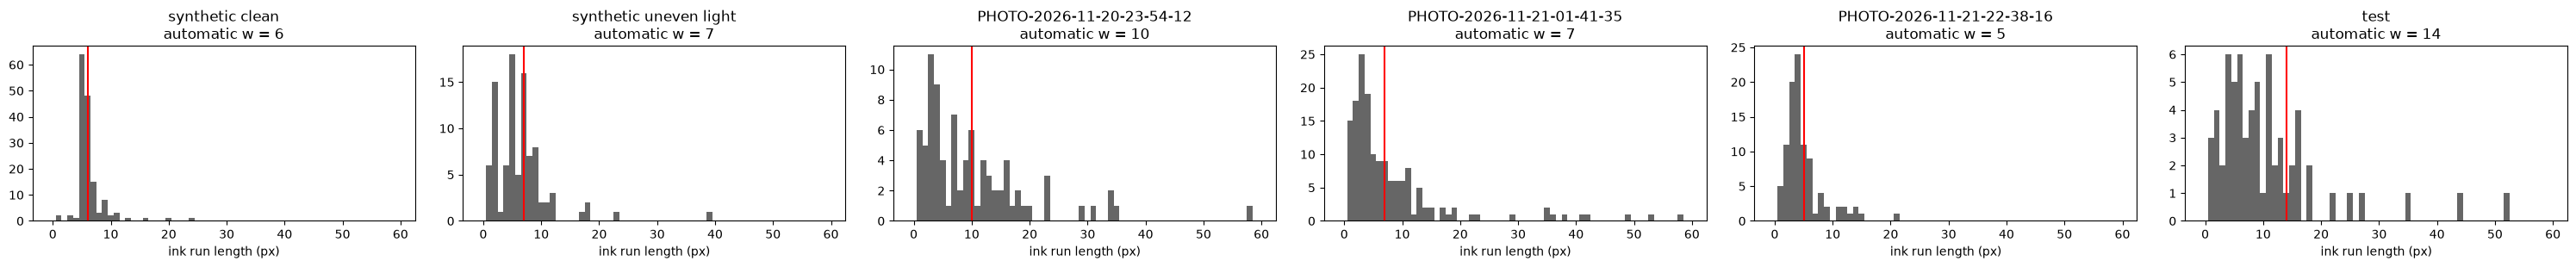

σ_n = 2.38 -> C0 ≈ 6.0   (frozen C in src: 9)


In [3]:
fig, ax = plt.subplots(1, len(prepared), figsize=(5 * len(prepared), 3.2))
for a, (name, gray) in zip(ax, prepared.items()):
    w, runs, *_ = at.estimate_stroke_width(gray, return_runs=True)
    a.hist(runs, bins=np.arange(0, 61) - 0.5, color="0.4"); a.axvline(w, color="r")
    a.set_title(f"{name}\nautomatic w = {w:g}"); a.set_xlabel("ink run length (px)")
plt.tight_layout(); plt.show()

photo = prepared[list(inputs)[2]]
sigma_n = np.std(photo[820:860, 900:940])           # ink-free 40×40 paper patch
print(f"σ_n = {sigma_n:.2f} -> C0 ≈ {2.5 * sigma_n:.1f}   (frozen C in src: {at.C})")

Automatic `w` is ≈ 6–7 on the synthetic images (true ≈ 5) but **10 on photo 1**, where by eye it is 4–5: Otsu fails on the photos, so its mask holds the page border, spiral holes and shadow rather than strokes. The frozen rule therefore uses the eye-checked `w = 4` → block 33. `C` is frozen in `src/adaptive_thresholding.py` (currently set by hand above the 2.5·σ_n estimate).

## 2. Sweep on photo 1 (`block ∈ {5w, 8w, 12w}` × `C ∈ {C/2, C, 2C}`)

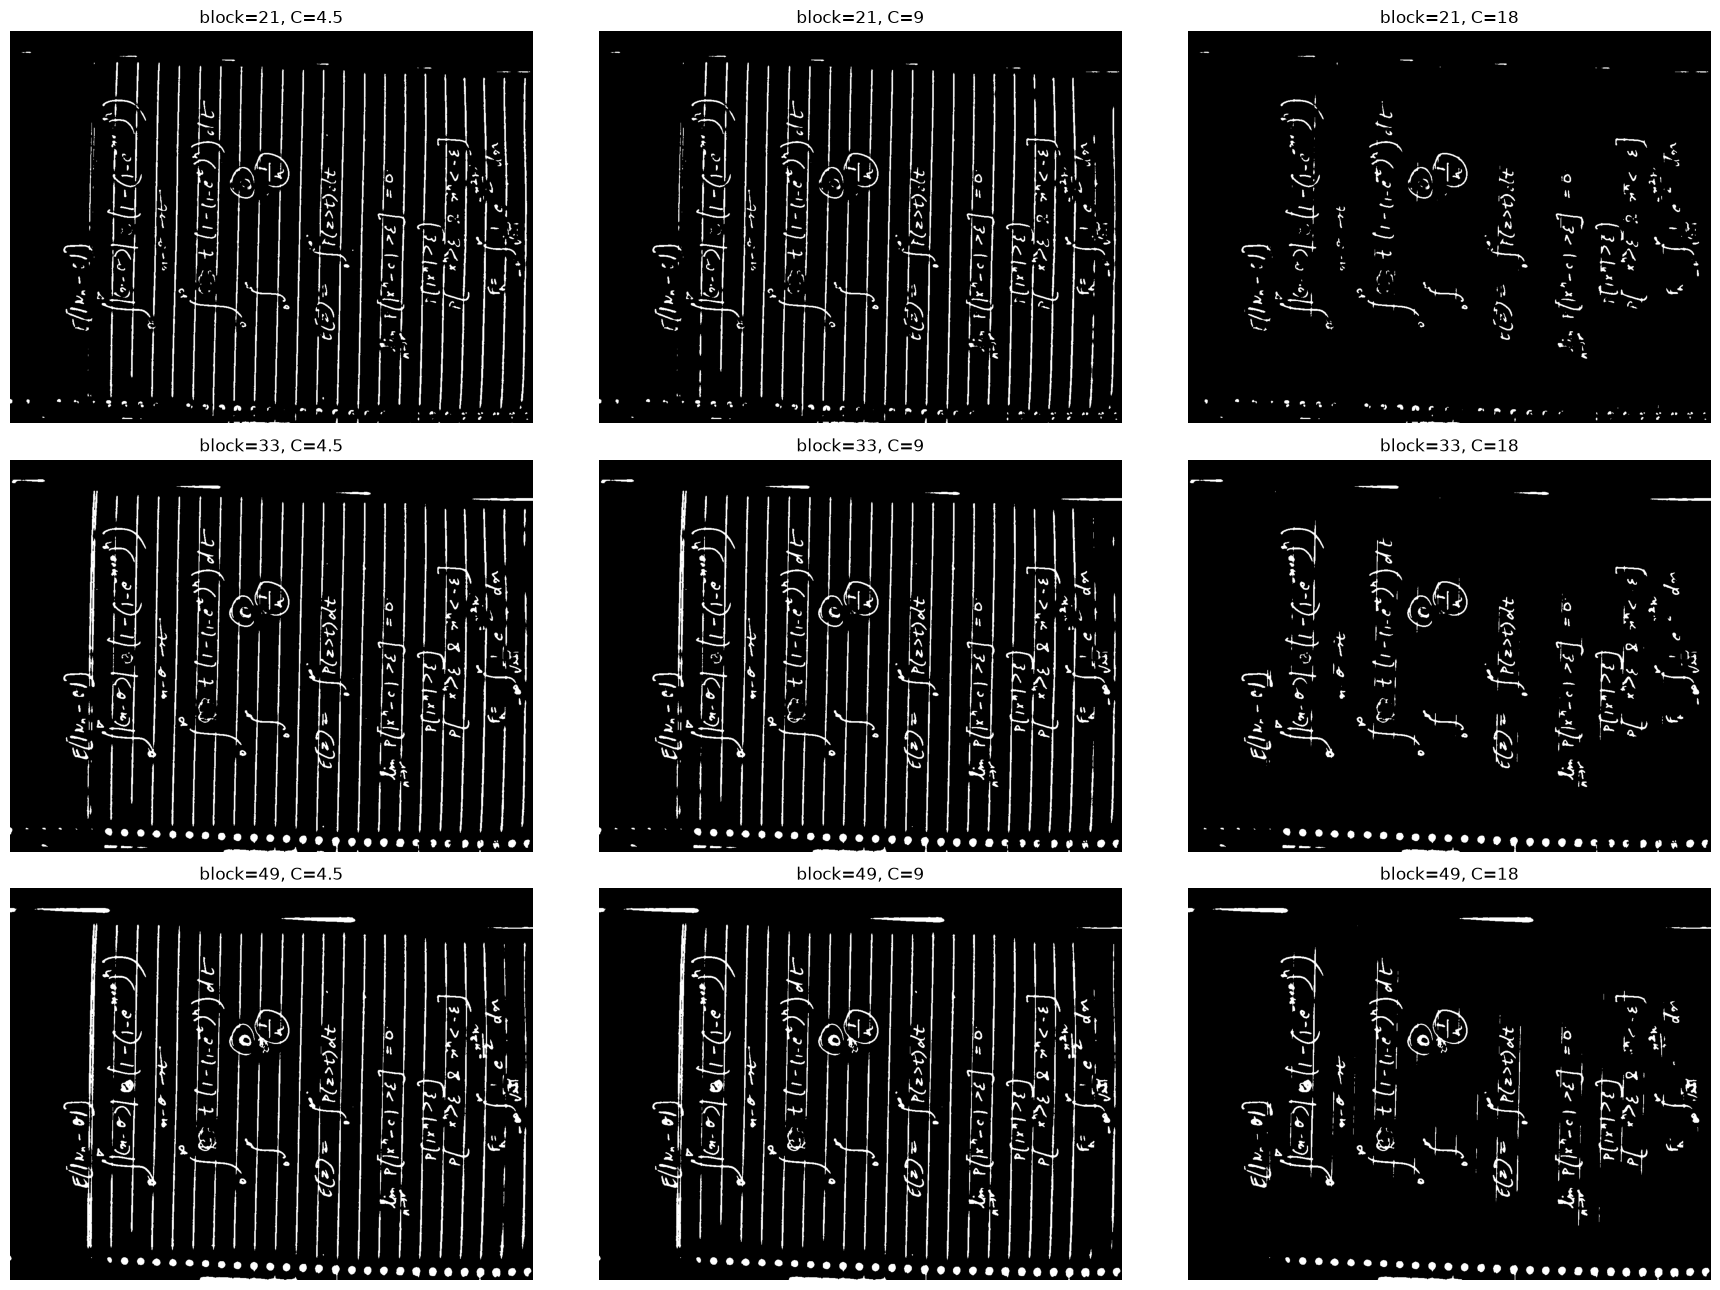

In [4]:
fig, ax = plt.subplots(3, 3, figsize=(18, 13))
for i, b in enumerate(at.odd(k * at.STROKE_W) for k in (5, 8, 12)):
    for j, c in enumerate((at.C / 2, at.C, 2 * at.C)):
        ax[i, j].imshow(at.adaptive_otsu(photo, b, c)[0], cmap="gray")
        ax[i, j].set_title(f"block={b}, C={c:g}"); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

## 3. `run_otsu` vs `run_adaptive` (frozen and estimated parameters)

`run_adaptive` always estimates: a first adaptive-Otsu pass with the frozen parameters gives an ink mask; from it `w` = median ink-run length, `σ_n` = median std of ink-free `block × block` windows; then block = odd(8w), C = 4·σ_n.

Panels: input | `run_otsu` | `adaptive_otsu` frozen | `run_adaptive` estimated | threshold map T (frozen) | valid tiles (frozen; white = Otsu threshold used, black = blank tile → all paper) | diff map.
Diff map (frozen vs Otsu): white = ink in both, green = adaptive only, red = Otsu only (Otsu output resized to the adaptive size only for this map).

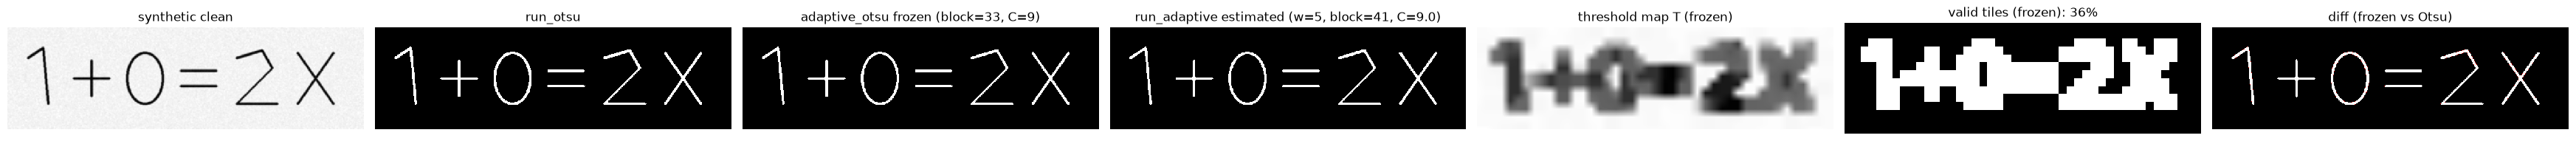

synthetic clean: ink % Otsu = 4.4, adaptive frozen = 4.3, estimated = 4.3, adaptive-only = 0.0, Otsu-only = 0.2


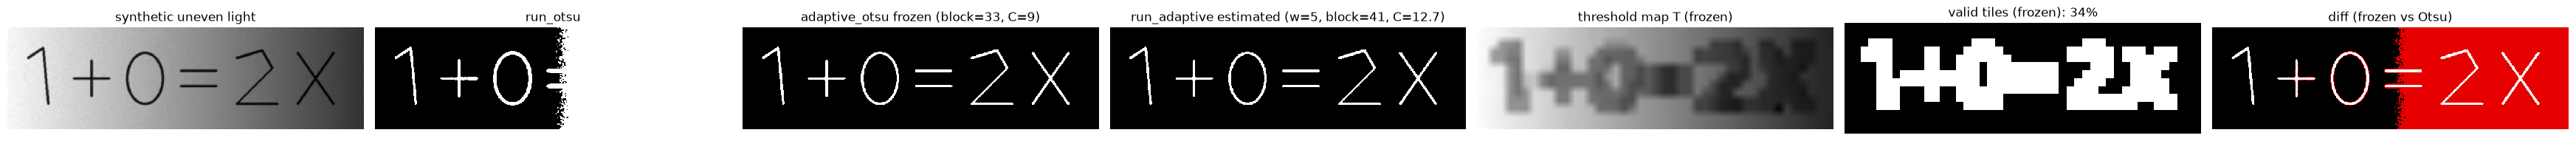

synthetic uneven light: ink % Otsu = 50.4, adaptive frozen = 4.3, estimated = 4.3, adaptive-only = 0.0, Otsu-only = 46.1


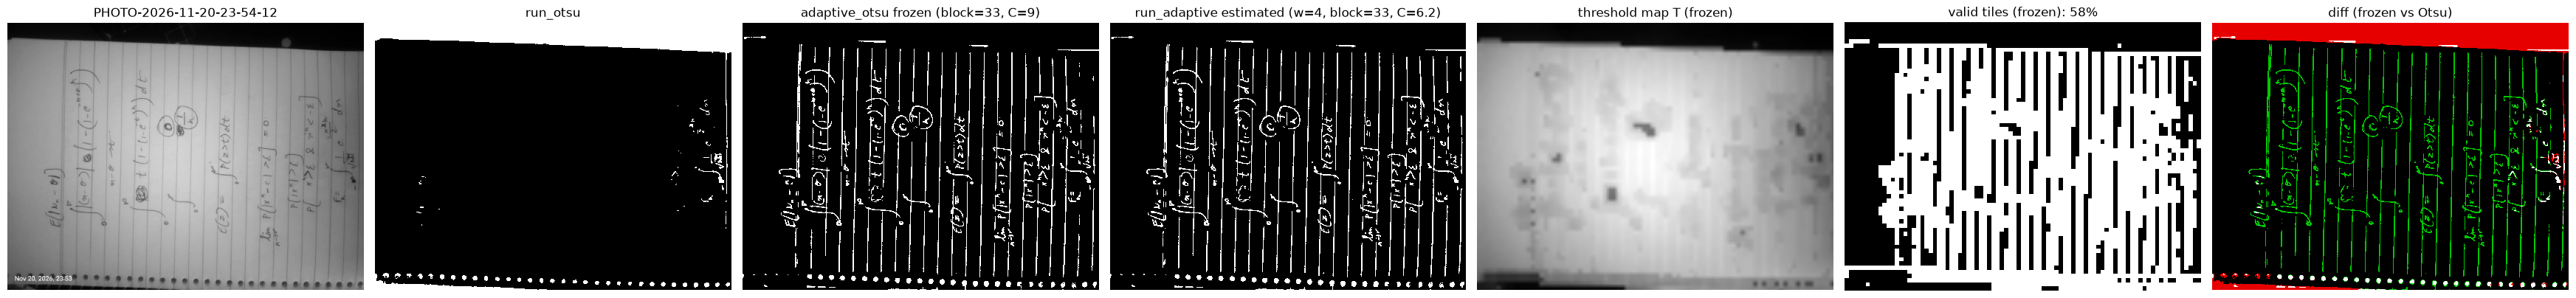

PHOTO-2026-11-20-23-54-12: ink % Otsu = 10.0, adaptive frozen = 8.2, estimated = 8.4, adaptive-only = 7.3, Otsu-only = 9.0


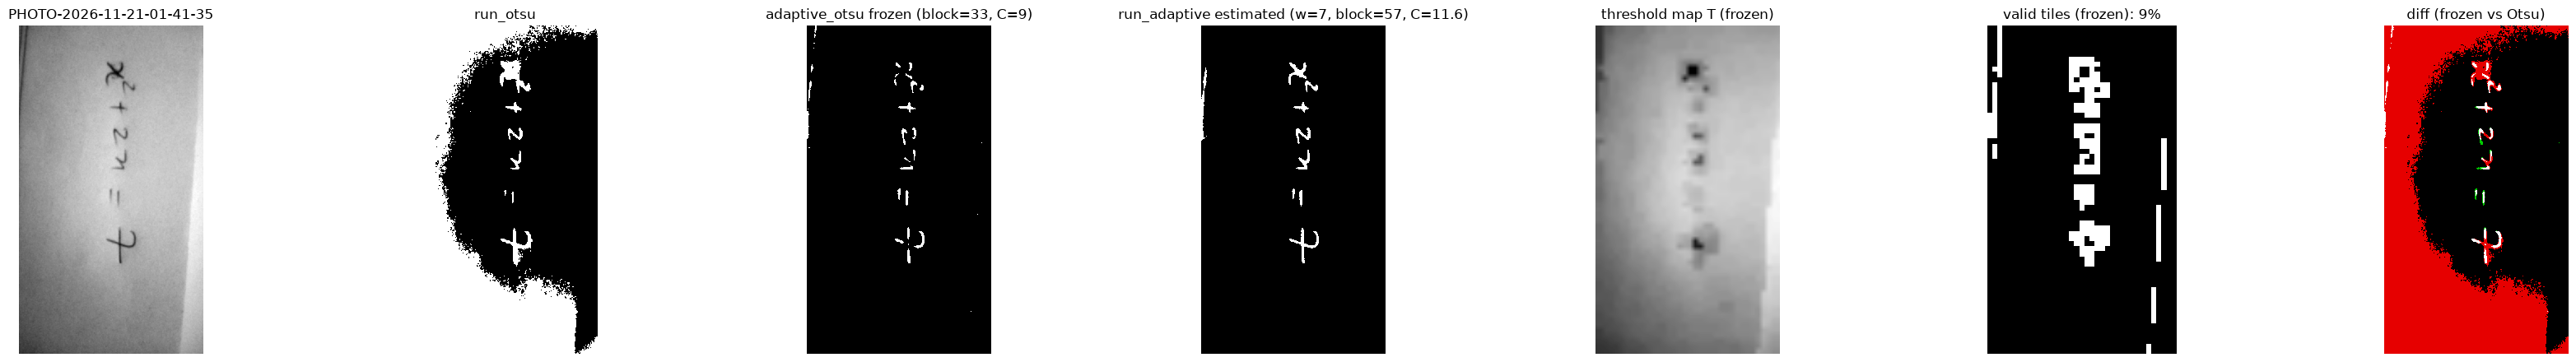

PHOTO-2026-11-21-01-41-35: ink % Otsu = 43.3, adaptive frozen = 1.0, estimated = 1.5, adaptive-only = 0.1, Otsu-only = 42.4


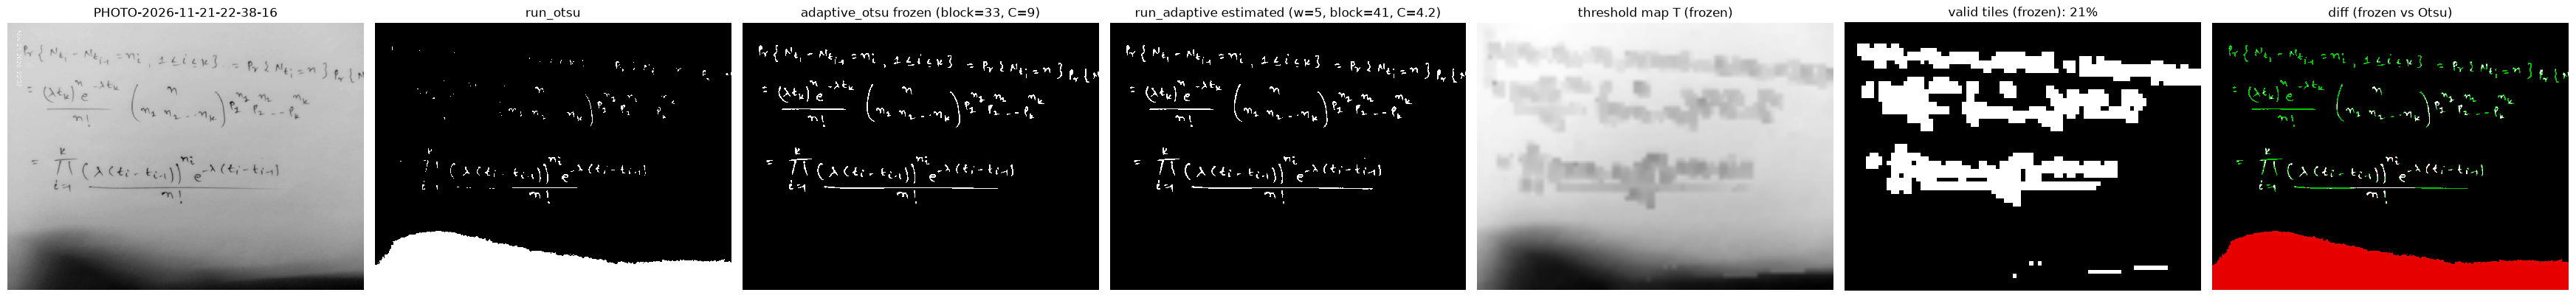

PHOTO-2026-11-21-22-38-16: ink % Otsu = 15.5, adaptive frozen = 2.1, estimated = 2.1, adaptive-only = 1.4, Otsu-only = 14.7


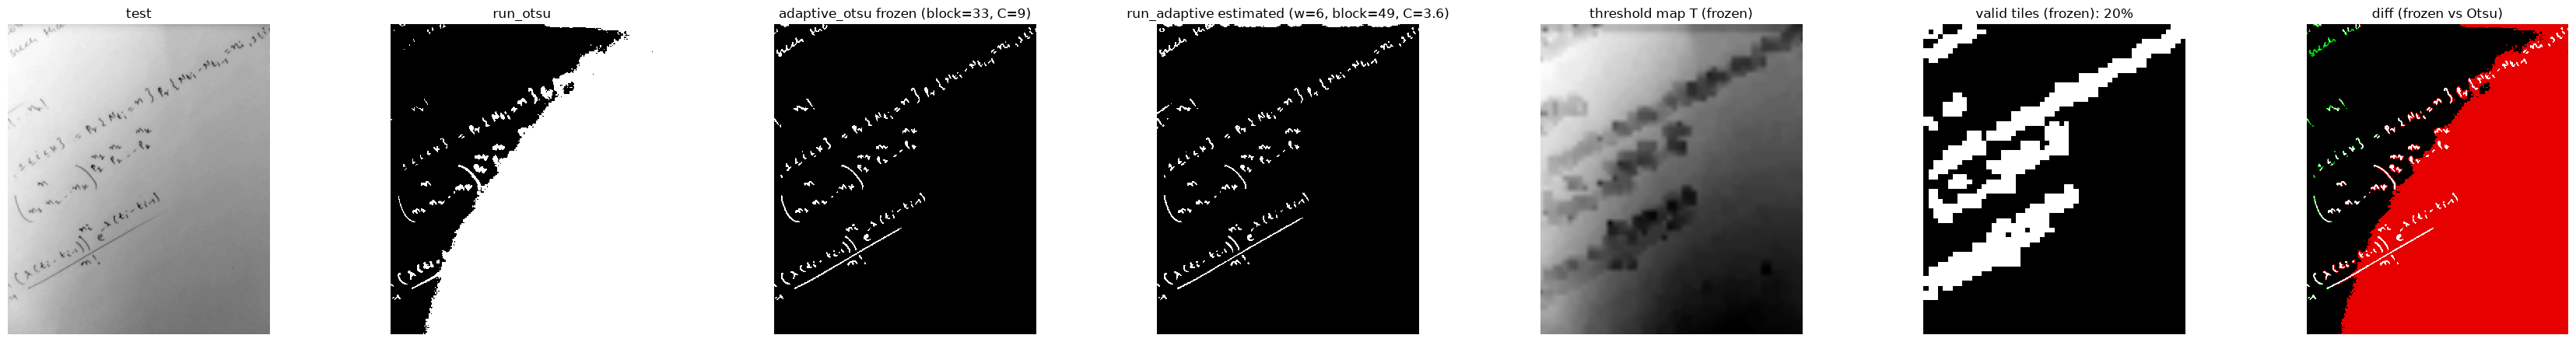

test: ink % Otsu = 59.9, adaptive frozen = 2.2, estimated = 2.7, adaptive-only = 0.3, Otsu-only = 58.0


In [5]:
for name, src in inputs.items():
    adapt, T, tiles = at.adaptive_otsu(prepared[name], return_tiles=True)        # frozen BLOCK / C
    adapt_est, est = at.run_adaptive(src, height(name), return_params=True)  # always estimated
    otsu = run_otsu(src)
    otsu = cv2.resize(otsu, adapt.shape[::-1], interpolation=cv2.INTER_NEAREST)
    diff = np.zeros(adapt.shape + (3,), np.uint8)
    diff[(adapt > 0) & (otsu > 0)] = 255
    diff[(adapt > 0) & (otsu == 0)] = (0, 200, 0)
    diff[(otsu > 0) & (adapt == 0)] = (230, 0, 0)

    panels = {name: prepared[name], "run_otsu": otsu, f"adaptive_otsu frozen (block={at.BLOCK}, C={at.C})": adapt,
              f"run_adaptive estimated (w={est['stroke_w']:g}, block={est['block']}, C={est['C']})": adapt_est,
              "threshold map T (frozen)": T,
              f"valid tiles (frozen): {100 * tiles['valid'].mean():.0f}%": tiles["valid"],
              "diff (frozen vs Otsu)": diff}
    fig, ax = plt.subplots(1, 7, figsize=(35, 4.5))
    for a, (title, im) in zip(ax, panels.items()):
        a.imshow(im, cmap="gray", interpolation="nearest"); a.set_title(title); a.axis("off")
    plt.tight_layout(); plt.show()
    print(f"{name}: ink % Otsu = {100 * (otsu > 0).mean():.1f}, adaptive frozen = {100 * (adapt > 0).mean():.1f}, estimated = {100 * (adapt_est > 0).mean():.1f}, "
          f"adaptive-only = {100 * (diff[..., 1] == 200).mean():.1f}, Otsu-only = {100 * (diff[..., 0] == 230).mean():.1f}")

## 4. Observations (adaptive Otsu)

| Image | `run_otsu` | `run_adaptive` (adaptive Otsu, estimated params) |
|---|---|---|
| Synthetic clean | clean strokes | same as Otsu (ink 4.3 % vs 4.4 %), no speckle |
| Synthetic uneven light | dark right side becomes ink, `=2X` lost | all symbols recovered, same ink % as the clean image |
| Photo 1 (dim, lined) | t* set by the dark background; writing lost | writing and ruled lines recovered; page edge and spiral holes still ink |
| Photo 2 (`x²+2x=7`, shadow) | shadowed half becomes ink | clean expression (with the frozen block 33 / C 9 strokes break; the estimated block 57 / C 11.6 fixes it); thin paper edge on the left |
| Photo 3 (upright derivation) | shadow at the bottom becomes ink, faint strokes lost | clean, shadow / table edge at the bottom not marked |
| Photo 4 (`test.png`, tilted) | dark lower-right region becomes ink, text partly lost | clean text; page-edge bar at the top |

- vs adaptive mean (previous version): strokes are **thinner** (threshold at the Otsu midpoint instead of just below the paper level).
- **Tile check** (spec's per-tile contrast gate): with only the gap ≥ C test, the soft shadow at the bottom of photo 3 passes (gap 5–15 vs C ≈ 4) and Otsu splits it into large ink blobs. Adding dark-class fraction ≤ 0.35 removes it (shadow / texture windows split ~50/50, ink is a minority; 0.25 gave the same results). Otsu's separability η = σ_B²/σ_T² did **not** separate them (text ≈ 0.8, shadow 0.7–0.8, because of the σ = 1 pre-blur).
- **Blank tiles = paper** (threshold = darkest pixel − 1) instead of the earlier adaptive-mean fallback (window mean − C): removes the remaining speckled band along photo 3's bottom edge, and Step 2 levels all 4 photos (photo 1 −88.8°, r = 3.63; photo 4 −29.8°, r = 2.81 — just above `R_MIN`). Filling blank tiles with the nearest valid tile's threshold instead produced rectangular false blobs in shadows.
- **Global cutoff `T_g` (spec option 1 / 2) tested and dropped:** ink in bright parts of a phone photo is lighter than paper in dark parts (`test.png`: 10 % of ink > 191, median paper 175). Ink kept on photos 1–4: T_g = P − 6σ_n → 52 / 74 / 95 / 61 %, T_g = P → 69 / 96 / 99 / 73 %, P + 20 → 94 / 100 / 100 / 97 %, P + 30 → 99–100 % but then it removes almost nothing. No single global value keeps the writing and removes false ink.
- **Speck filter tested and dropped from Step 1** (blobs < 0.25·w² removed ≤ 0.8 % of ink; 0.5·w² removed subscript `i` dots) — tiny-blob removal belongs to Step 4.
- Sweep: C = 18 removes most ruled lines but starts to thin faint strokes; block size (21–49) changes little.
- Not solved by thresholding: ruled lines, spiral holes, page edges, timestamp (need a later step: border / large-blob filter). Parameters are checked on 4 photos only.